# JS11 – Klasifikasi 2: Praktikum 3
## SVM pada Data Overlapping dan Pengaruh Parameter C

**Tujuan praktikum**

1. Memahami masalah data yang tumpang tindih (overlapping).
2. Menerapkan **soft margin** melalui parameter `C`.
3. Menganalisis pengaruh `C` terhadap margin, jumlah support vector, dan akurasi.
4. Menggunakan validasi silang untuk memilih `C` secara lebih objektif.
5. Menjelaskan trade-off antara margin lebar dan pelanggaran margin.

**Tentang data:** Data dibuat dengan `make_blobs`, 100 sampel, 2 pusat kelas, dan `cluster_std` yang cukup besar sehingga sebagian titik berada di area kelas lain. Pada data seperti ini, hard margin tidak mungkin dilakukan; SVM harus menggunakan soft margin.

> Parameter `C` adalah penalti untuk setiap titik yang melanggar margin. `C` kecil memberi margin lebar dengan toleransi kesalahan lebih besar. `C` besar memberi margin sempit dan berusaha keras mengklasifikasikan semua data latih dengan benar.

### 0. Import library dan fungsi plotting

In [1]:
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.svm import SVC

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 6)

print("Python  :", platform.python_version())
print("NumPy   :", np.__version__)
print("pandas  :", pd.__version__)
print("seaborn :", sns.__version__)

Python  : 3.12.3
NumPy   : 2.5.4
pandas  : 3.0.6
seaborn : 0.13.2


In [2]:
def plot_svc_decision_function(model, ax=None, plot_support=True):
    '''Plot decision boundary, margin, dan support vector untuk SVM 2D.'''
    if ax is None:
        ax = plt.gca()

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X_grid = np.meshgrid(y, x)
    xy = np.vstack([X_grid.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X_grid.shape)

    ax.contour(
        X_grid,
        Y,
        P,
        colors="k",
        levels=[-1, 0, 1],
        alpha=0.5,
        linestyles=["--", "-", "--"],
    )

    if plot_support:
        ax.scatter(
            model.support_vectors_[:, 0],
            model.support_vectors_[:, 1],
            s=300,
            linewidth=1,
            facecolors="none",
            edgecolors="k",
            label="Support vector",
        )

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

### 1. Data yang tumpang tindih

Data dibuat dengan `cluster_std=1.2` agar tumpang tindih antar kelas terlihat jelas. Pada kondisi ini, tidak ada garis lurus yang dapat memisahkan kedua kelas tanpa kesalahan.

Distribusi kelas: [50 50]


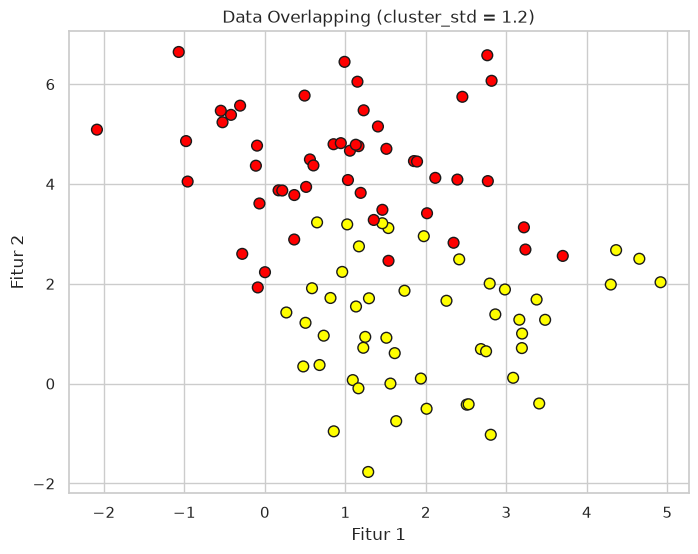

In [3]:
X_overlap, y_overlap = make_blobs(
    n_samples=100,
    centers=2,
    random_state=0,
    cluster_std=1.2,
)

print("Distribusi kelas:", np.bincount(y_overlap))

plt.figure(figsize=(8, 6))
plt.scatter(
    X_overlap[:, 0],
    X_overlap[:, 1],
    c=y_overlap,
    s=60,
    cmap="autumn",
    edgecolor="k",
)
plt.title("Data Overlapping (cluster_std = 1.2)")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.show()

### 2. Soft margin: membandingkan C = 10 dan C = 0.1

Untuk memperjelas efek margin, kita gunakan data dengan `cluster_std=0.8`. Pada data ini kedua kelas masih dapat dipisahkan dengan benar, tetapi posisi margin dan jumlah support vector sangat dipengaruhi oleh `C`.

Kita juga menghitung **lebar margin** secara kuantitatif:

$$
\text{lebar margin} = \frac{2}{\|w\|}
$$

dengan `w` adalah vektor bobot hyperplane.

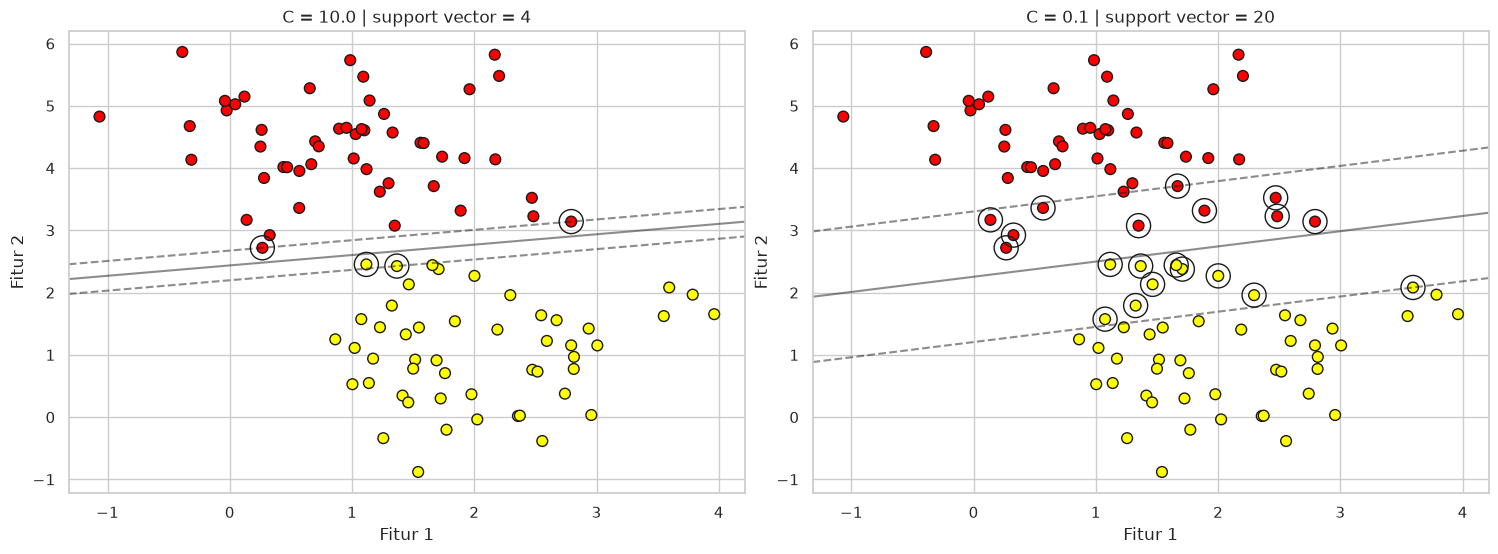

,C,Akurasi latih,Jumlah support vector,Lebar margin
0,10.0,1.0,4,0.4702
1,0.1,1.0,20,2.0380


In [4]:
X, y = make_blobs(
    n_samples=100,
    centers=2,
    random_state=0,
    cluster_std=0.8,
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

hasil_c = []
for ax, C in zip(axes, [10.0, 0.1]):
    model = SVC(kernel="linear", C=C)
    model.fit(X, y)

    w = model.coef_[0]
    margin_width = 2 / np.linalg.norm(w)
    hasil_c.append({
        "C": C,
        "Akurasi latih": model.score(X, y),
        "Jumlah support vector": len(model.support_vectors_),
        "Lebar margin": margin_width,
    })

    ax.scatter(X[:, 0], X[:, 1], c=y, s=60, cmap="autumn", edgecolor="k")
    plot_svc_decision_function(model, ax)
    ax.set_title(f"C = {C:.1f} | support vector = {len(model.support_vectors_)}")
    ax.set_xlabel("Fitur 1")
    ax.set_ylabel("Fitur 2")

plt.show()

pd.DataFrame(hasil_c).round(4)

**Interpretasi C**

- `C = 10` memberi penalti besar pada pelanggaran. Margin menjadi lebih sempit dan jumlah support vector lebih sedikit. Model berusaha memisahkan semua titik latih dengan benar.
- `C = 0.1` memberi penalti lebih kecil. Margin menjadi lebih lebar dan lebih banyak titik menjadi support vector karena sebagian titik diizinkan berada di dalam margin atau di sisi yang salah.
- Pada data yang mudah dipisahkan, keduanya bisa mencapai akurasi latih 1,0. Perbedaannya terletak pada **lebar margin** dan **kompleksitas model**, bukan hanya akurasi.

### 3. Validasi silang untuk memilih C

Akurasi data latih saja tidak cukup. Kita uji beberapa nilai `C` dengan 5-fold stratified cross-validation.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

nilai_c = [0.001, 0.01, 0.1, 1, 10, 100]
hasil_cv = []

for C in nilai_c:
    scores = cross_val_score(
        SVC(kernel="linear", C=C),
        X,
        y,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
    )
    hasil_cv.append({
        "C": C,
        "CV accuracy": scores.mean(),
        "CV std": scores.std(),
    })

hasil_cv = pd.DataFrame(hasil_cv)
hasil_cv.round(4)

,C,CV accuracy,CV std
0,0.001,0.98,0.0245
1,0.010,0.99,0.0200
2,0.100,1.00,0.0000
3,1.000,0.99,0.0200
4,10.000,1.00,0.0000
5,100.000,1.00,0.0000


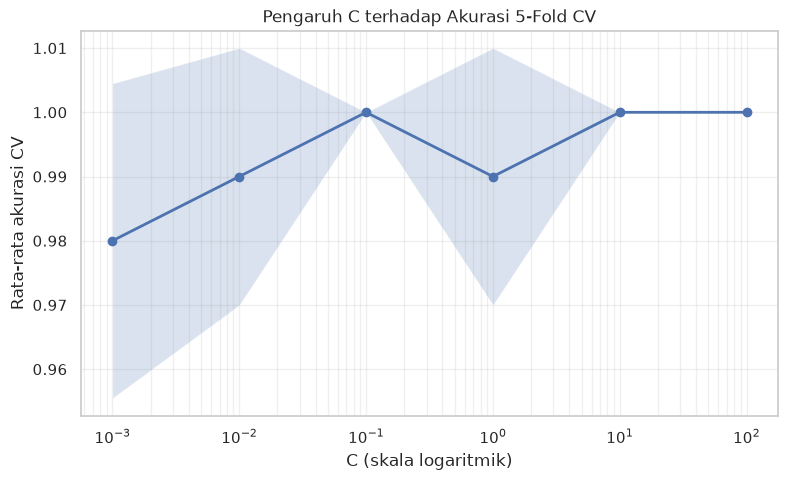

In [6]:
plt.figure(figsize=(9, 5))
plt.semilogx(hasil_cv["C"], hasil_cv["CV accuracy"], marker="o", linewidth=2)
plt.fill_between(
    hasil_cv["C"],
    hasil_cv["CV accuracy"] - hasil_cv["CV std"],
    hasil_cv["CV accuracy"] + hasil_cv["CV std"],
    alpha=0.2,
)
plt.title("Pengaruh C terhadap Akurasi 5-Fold CV")
plt.xlabel("C (skala logaritmik)")
plt.ylabel("Rata-rata akurasi CV")
plt.grid(True, which="both", alpha=0.3)
plt.show()

Pada dataset yang relatif mudah ini, kurva CV cukup datar untuk `C ≥ 0.1`. Nilai `C` yang sangat kecil (`0.001`) mulai menurun karena margin terlalu lebar dan model menjadi underfitting. Karena CV tidak membedakan banyak nilai C secara signifikan, pemilihan C sebaiknya juga mempertimbangkan lebar margin, jumlah support vector, dan tujuan aplikasi.

### 4. Kesimpulan

1. Data overlapping tidak dapat ditangani dengan hard margin; diperlukan **soft margin**.
2. Parameter `C` mengontrol trade-off antara margin lebar dan jumlah pelanggaran.
3. `C` kecil → margin lebar, lebih banyak support vector, toleransi kesalahan lebih besar.
4. `C` besar → margin sempit, lebih sedikit support vector, berusaha keras mengklasifikasikan semua data latih.
5. Akurasi latih tidak cukup untuk memilih `C`; validasi silang dan pemeriksaan margin diperlukan.
6. Pada eksperimen ini, `C` sekitar `0.1` sampai `10` memberi performa CV yang tinggi, dengan `C=0.1` menghasilkan margin yang jauh lebih lebar daripada `C=10`.

**Keterbatasan**

- Data hanya 100 titik dan mudah dipisahkan, sehingga banyak nilai C memberi akurasi tinggi.
- Lebar margin pada SVM linear hanya berlaku untuk kernel linear.
- Pada data nyata, distribusi kelas dan biaya kesalahan harus dipertimbangkan saat memilih C.

### Referensi

- Modul Praktikum Pembelajaran Mesin JS11 – Klasifikasi 2, Politeknik Negeri Malang. https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js11-klasifikasi-2
- `scikit-learn` – SVM: parameter C. https://scikit-learn.org/stable/modules/svm.html#parameters-of-the-svc
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning*. Springer.